<div style="
    background-color: #7BAFD4;
    border-radius: 18px;
    padding: 22px 26px;
    display: flex;
    align-items: center;
    gap: 24px;
    margin-bottom: 18px;
">
    <img src="../week02/week02_module1_day2/592_avatar_lr.png" alt="GEOG 592"
        style="width:110px;height:110px;border-radius:22px;">
    <div>
        <div style="
            font-family: Impact, 'Arial Black', Arial, sans-serif;
            font-size: 42px;
            font-weight: 900;
            letter-spacing: 2px;
            line-height: 1;
            color: white;
        ">GEOG 592</div>
        <div style="
            font-family: Arial, Helvetica, sans-serif;
            font-size: 22px;
            font-weight: 700;
            color: #13294B;
            margin-top: 8px;
        ">GIS Programming</div>
        <div style="
            font-family: Arial, Helvetica, sans-serif;
            font-size: 16px;
            color: #13294B;
            margin-top: 6px;
        ">Cartography example legend</div>
    </div>
</div>



In [1]:
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt

<Axes: >

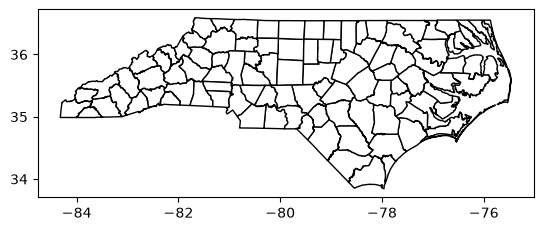

In [2]:
# getting the US census data

url_0 = "https://www2.census.gov/geo/tiger/GENZ2024/shp/" # url for census tiger data 
url_county = "cb_2024_us_county_500k.zip" # county level
url_state = "cb_2024_us_state_500k.zip" # state level 


## Code for county level data 

counties = gpd.read_file(url_0+url_county)
nc_counties = counties.loc[counties["STATEFP"] == "37"].copy()
nc_counties.plot(edgecolor="black", facecolor="white")

<Axes: >

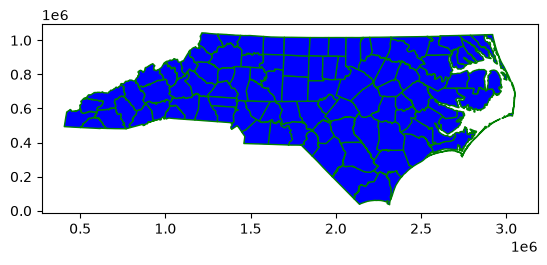

In [3]:
## changing the projection of a layer
ncc_copy = nc_counties.to_crs(epsg = 6543).copy()
ncc_copy.plot(edgecolor = "green", facecolor = "blue") ## the units have changed, now we are in feet (most of the local projections are in feet)

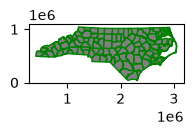

In [4]:
def ncplot(ax, stroke, fill):
    ncc_copy.plot(ax = ax, edgecolor = stroke, facecolor = fill) ## ax = ax allows the shape to be squished

fig, ax = plt.subplots(figsize = (2, 1)) ## width, height in that order
ncplot(ax, 'green', 'gray')
plt.show()

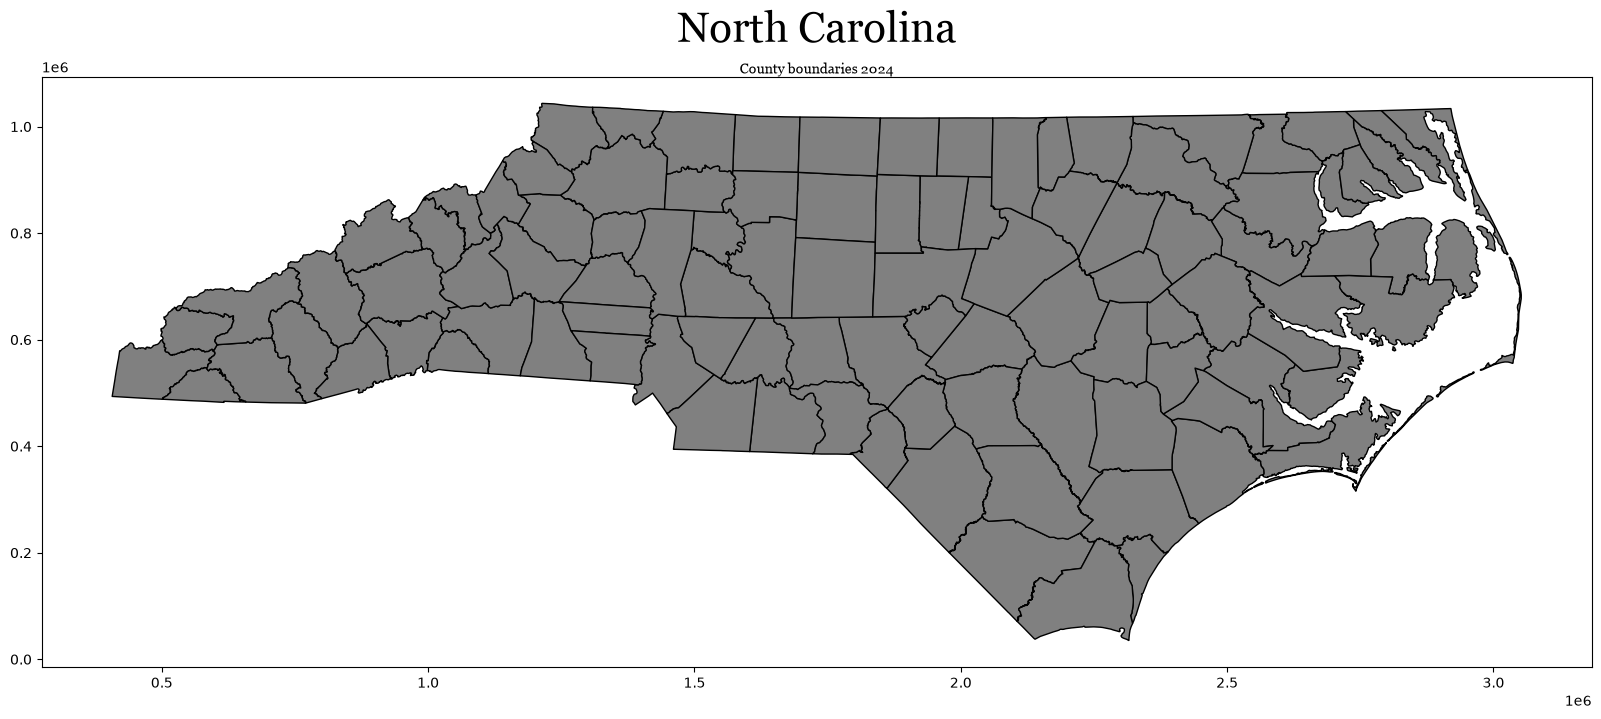

In [5]:
fig, ax = plt.subplots(figsize = (20, 10)) ## width, height in that order
ncplot(ax, 'black', 'gray')
ax.set_title("North Carolina", fontsize = 30, pad = 25, fontname = "Georgia")
ax.text(
    .5, 1.0, "County boundaries 2024", transform=ax.transAxes, ha = 'center', va = 'bottom', fontsize = 10, fontname = 'Georgia'
)
plt.show()

In [6]:
ncc_copy

,STATEFP,COUNTYFP,COUNTYNS,GEOIDFQ,GEOID,NAME,NAMELSAD,STUSPS,STATE_NAME,LSAD,ALAND,AWATER,geometry
90,37,047,01026339,0500000US37047,37047,Columbus,Columbus County,NC,North Carolina,06,2429920494,43711694,"POLYGON ((1978481.879 199930.366, 1979179.073 ..."
91,37,039,01008545,0500000US37039,37039,Cherokee,Cherokee County,NC,North Carolina,06,1179842036,28813680,"POLYGON ((408779.421 505506.597, 408786.42 505..."
92,37,149,01008579,0500000US37149,37149,Polk,Polk County,NC,North Carolina,06,615606325,1964035,"POLYGON ((997042.881 555579.496, 997049.933 55..."
93,37,009,01008535,0500000US37009,37009,Ashe,Ashe County,NC,North Carolina,06,1104023356,8058446,"POLYGON ((1193571.583 980437.246, 1194562.461 ..."
94,37,055,01026133,0500000US37055,37055,Dare,Dare County,NC,North Carolina,06,992558552,3000513281,"MULTIPOLYGON (((2968803.433 811517.819, 297128..."
...,...,...,...,...,...,...,...,...,...,...,...,...,...
3001,37,069,01008553,0500000US37069,37069,Franklin,Franklin County,NC,North Carolina,06,1273761678,7173998,"POLYGON ((2134342.078 839845.822, 2134479.82 8..."
3012,37,097,01008565,0500000US37097,37097,Iredell,Iredell County,NC,North Carolina,06,1487784939,59453223,"POLYGON ((1374327.812 744224.956, 1375216.065 ..."
3045,37,187,01026331,0500000US37187,37187,Washington,Washington County,NC,North Carolina,06,897456201,195282199,"POLYGON ((2638938.588 723898.852, 2640001.911 ..."
3087,37,071,01008554,0500000US37071,37071,Gaston,Gaston County,NC,North Carolina,06,921389625,20549066,"POLYGON ((1268485.378 616765.02, 1282096.491 6..."


In [7]:
# creating a loop that assigns the county names on the map
for name in ncc_copy["NAME"]: 
    point = ncc_copy["geometry"][ncc_copy["NAME"] == name]
    print(name)
    print(point.x)
    # print(point.geometry.y)

Columbus


ValueError: x attribute access only provided for Point geometries